# 01 - First EDA (California subset)

Questions for this first pass:

1. How many series are there, and how do they split by store and category?
2. What date range does the data cover?
3. How intermittent is demand, i.e. what share of days have zero sales?

Input: `data/processed/*.parquet`, built with `uv run python -m m5_demand_forecasting.data`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from m5_demand_forecasting.data import ID_COLS, PROCESSED_DIR

plt.rcParams.update(
    {
        "figure.figsize": (9, 3.5),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
    }
)
COLOR = "#2a6fb0"

In [2]:
sales = pd.read_parquet(PROCESSED_DIR / "sales_wide.parquet")
calendar = pd.read_parquet(PROCESSED_DIR / "calendar.parquet")
day_cols = [c for c in sales.columns if c.startswith("d_")]
sales[ID_COLS].head()

,id,item_id,dept_id,cat_id,store_id,state_id
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA


## 1. Series count

In [3]:
print(f"series: {len(sales):,}")
print(f"items:  {sales['item_id'].nunique():,}")
print(f"stores: {sales['store_id'].nunique()}")
sales.pivot_table(index="cat_id", columns="store_id", values="id", aggfunc="count", margins=True)

series: 12,196
items:  3,049
stores: 4


store_id,CA_1,CA_2,CA_3,CA_4,All
cat_id,,,,,
FOODS,1437,1437,1437,1437,5748
HOBBIES,565,565,565,565,2260
HOUSEHOLD,1047,1047,1047,1047,4188
All,3049,3049,3049,3049,12196


## 2. Date range

In [4]:
dates = calendar.set_index("d")["date"]
first, last = dates[day_cols[0]], dates[day_cols[-1]]
print(f"sales days:    {len(day_cols):,} ({first:%Y-%m-%d} to {last:%Y-%m-%d})")
print(f"calendar days: {len(calendar):,} (to {calendar['date'].max():%Y-%m-%d})")

sales days:    1,941 (2011-01-29 to 2016-05-22)
calendar days: 1,969 (to 2016-06-19)


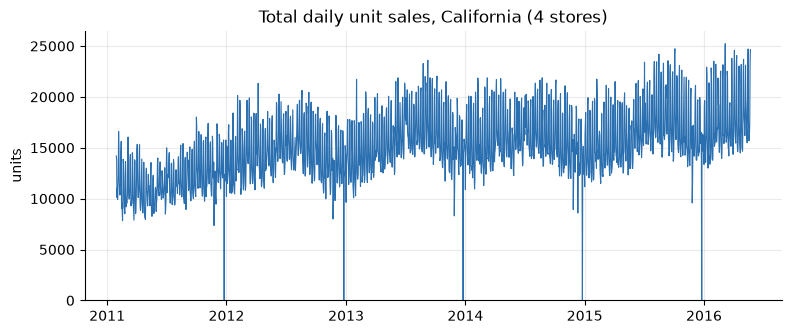

2013-12-25       5
2012-12-25       6
2014-12-25       6
2015-12-25       6
2011-12-25       8
2011-11-24    7356
dtype: int64

In [5]:
daily_total = sales[day_cols].sum()
daily_total.index = dates[day_cols].values

fig, ax = plt.subplots()
ax.plot(daily_total.index, daily_total.values, color=COLOR, linewidth=0.8)
ax.set_title("Total daily unit sales, California (4 stores)")
ax.set_ylabel("units")
ax.set_ylim(bottom=0)
plt.show()

daily_total.nsmallest(6)

## 3. Share of zero-sales days

Many items were not on sale at the start of the dataset, so their series begin with a long run of zeros. Two views are therefore useful: all days, and only the days from each series' first sale onwards (its active period).

In [6]:
values = sales[day_cols].to_numpy()
has_sale = values > 0
first_sale = has_sale.argmax(axis=1)
active = np.arange(values.shape[1]) >= first_sale[:, None]

zero_all = (values == 0).mean()
zero_active = ((values == 0) & active).sum() / active.sum()
print(f"zero-sales share, all days:      {zero_all:.1%}")
print(f"zero-sales share, active period: {zero_active:.1%}")
print(f"series with no sales at all:     {(~has_sale.any(axis=1)).sum()}")
print(f"median days before first sale:   {np.median(first_sale):.0f}")

zero-sales share, all days:      66.0%
zero-sales share, active period: 56.5%
series with no sales at all:     0
median days before first sale:   158


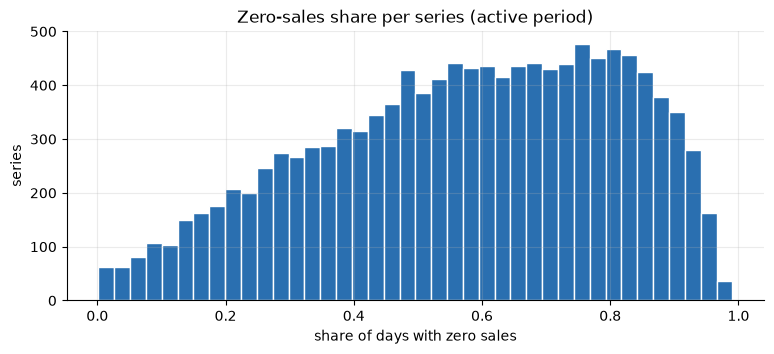

,series,zero_share,median_series_zero_share,median_daily_units
cat_id,,,,
FOODS,5748,0.480,0.508,1.035
HOBBIES,2260,0.685,0.749,0.356
HOUSEHOLD,4188,0.614,0.654,0.520


In [7]:
per_series = pd.DataFrame(
    {
        "cat_id": sales["cat_id"],
        "zeros": ((values == 0) & active).sum(axis=1),
        "active_days": active.sum(axis=1),
        "mean_daily_units": (values * active).sum(axis=1) / active.sum(axis=1),
    }
)
per_series["zero_share"] = per_series["zeros"] / per_series["active_days"]

fig, ax = plt.subplots()
ax.hist(per_series["zero_share"], bins=40, color=COLOR, edgecolor="white")
ax.set_title("Zero-sales share per series (active period)")
ax.set_xlabel("share of days with zero sales")
ax.set_ylabel("series")
plt.show()

by_cat = per_series.groupby("cat_id").agg(
    series=("zero_share", "size"),
    zeros=("zeros", "sum"),
    active_days=("active_days", "sum"),
    median_series_zero_share=("zero_share", "median"),
    median_daily_units=("mean_daily_units", "median"),
)
by_cat["zero_share"] = by_cat["zeros"] / by_cat["active_days"]
by_cat[["series", "zero_share", "median_series_zero_share", "median_daily_units"]].round(3)

## Takeaways

_To fill in after reading the numbers above._